In [20]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ahmadyasser7/dataco-smart-supply-chain-for-big-data-analysis/DataCoSupplyChainDataset.csv


In [21]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/ahmadyasser7/dataco-smart-supply-chain-for-big-data-analysis/DataCoSupplyChainDataset.csv


In [22]:
import sqlite3
import pandas as pd

# Load CSV using your verified Kaggle path
file_path = '/kaggle/input/datasets/ahmadyasser7/dataco-smart-supply-chain-for-big-data-analysis/DataCoSupplyChainDataset.csv'
df = pd.read_csv(file_path, encoding='latin1')

# Connect to SQLite database and write raw table
conn = sqlite3.connect('dataco_supply_chain.db')
df.to_sql('raw_orders', conn, if_exists='replace', index=False)

print("Data loaded into SQLite successfully.")

Data loaded into SQLite successfully.


In [23]:
clean_query = """
DROP TABLE IF EXISTS orders_clean;

CREATE TABLE orders_clean AS
SELECT
    "Order Id" AS order_id,
    "Order Item Id" AS order_item_id,
    "order date (DateOrders)" AS order_date,
    "shipping date (DateOrders)" AS shipping_date,
    "Shipping Mode" AS shipping_mode,
    CAST("Days for shipping (real)" AS INTEGER) AS days_shipping_real,
    CAST("Days for shipment (scheduled)" AS INTEGER) AS days_shipping_scheduled,
    "Delivery Status" AS delivery_status,
    CAST("Late_delivery_risk" AS INTEGER) AS late_delivery_risk,
    "Order Status" AS order_status,
    "Order Region" AS order_region,
    "Order Country" AS order_country,
    "Order City" AS order_city,
    "Market" AS market,
    "Category Name" AS category_name,
    "Product Name" AS product_name,
    CAST("Order Item Quantity" AS INTEGER) AS quantity,
    CAST("Sales" AS REAL) AS sales_amount,
    CAST("Order Item Profit Ratio" AS REAL) AS profit_ratio,
    CAST("Benefit per order" AS REAL) AS net_profit
FROM raw_orders
WHERE "Order Status" NOT IN ('CANCELED', 'SUSPECTED_FRAUD');
"""

conn.executescript(clean_query)

# Verify clean rows and null counts
verification_sql = """
SELECT 
    COUNT(*) AS total_clean_rows,
    SUM(CASE WHEN order_id IS NULL THEN 1 ELSE 0 END) AS null_order_ids,
    SUM(CASE WHEN shipping_mode IS NULL THEN 1 ELSE 0 END) AS null_shipping_modes,
    SUM(CASE WHEN net_profit IS NULL THEN 1 ELSE 0 END) AS null_profit
FROM orders_clean;
"""

verification_df = pd.read_sql_query(verification_sql, conn)
print(verification_df)

   total_clean_rows  null_order_ids  null_shipping_modes  null_profit
0            172765               0                    0            0


In [24]:
# Query 1: Delay Performance by Shipping Mode
q1 = """
SELECT 
    shipping_mode,
    COUNT(*) AS total_orders,
    SUM(late_delivery_risk) AS delayed_orders,
    ROUND(AVG(late_delivery_risk) * 100.0, 2) AS late_rate_pct,
    ROUND(AVG(days_shipping_real - days_shipping_scheduled), 2) AS avg_days_behind_schedule
FROM orders_clean
GROUP BY shipping_mode
ORDER BY late_rate_pct DESC;
"""

# Query 2: Bottleneck Markets (Volume vs Delays)
q2 = """
SELECT 
    market,
    COUNT(*) AS total_orders,
    ROUND(AVG(late_delivery_risk) * 100.0, 2) AS late_rate_pct,
    ROUND(SUM(net_profit), 2) AS total_market_profit
FROM orders_clean
GROUP BY market
ORDER BY late_rate_pct DESC;
"""

# Query 3: Financial Exposure (Profit on Delayed vs On-Time Orders)
q3 = """
SELECT 
    delivery_status,
    COUNT(*) AS total_shipments,
    ROUND(SUM(sales_amount), 2) AS total_revenue,
    ROUND(SUM(net_profit), 2) AS total_profit,
    ROUND(AVG(profit_ratio) * 100.0, 2) AS avg_profit_margin_pct
FROM orders_clean
GROUP BY delivery_status
ORDER BY total_shipments DESC;
"""

print("--- 1. Shipping Mode Performance ---")
print(pd.read_sql_query(q1, conn))
print("\n--- 2. Market Regional Delays ---")
print(pd.read_sql_query(q2, conn))
print("\n--- 3. Financial Impact by Delivery Status ---")
print(pd.read_sql_query(q3, conn))

--- 1. Shipping Mode Performance ---
    shipping_mode  total_orders  delayed_orders  late_rate_pct  \
0     First Class         26513           26513         100.00   
1    Second Class         33806           26987          79.83   
2        Same Day          9293            4454          47.93   
3  Standard Class        103153           41023          39.77   

   avg_days_behind_schedule  
0                      1.00  
1                      1.99  
2                      0.48  
3                     -0.01  

--- 2. Market Regional Delays ---
         market  total_orders  late_rate_pct  total_market_profit
0        Europe         48090          57.69           1131937.91
1          USCA         24627          57.41            539223.29
2  Pacific Asia         39585          57.38            826167.16
3         LATAM         49309          56.87           1069050.79
4        Africa         11154          56.84            240041.48

--- 3. Financial Impact by Delivery Status ---
   

---

## 3. Key Findings & Insights (Share)

1. **Systemic Failure in Expedited Shipping:**
   - **First Class:** Suffered a **100.0% late delivery rate** across all 26,513 orders, averaging 1.0 day past the scheduled window.
   - **Second Class:** Experienced a **79.8% late delivery rate** across 33,806 orders, averaging nearly 2 days behind schedule.
   - **Takeaway:** The breakdown is driven by unrealistic scheduling parameters in the Order Management System (OMS) rather than random transit friction.

2. **Standard Class Carries the Majority of Volume Reliably:**
   - Standard Class handles roughly 60% of total company volume (103,153 orders) with a late delivery rate of **39.8%** and an average delay of **-0.01 days** (delivering on or slightly ahead of schedule).

3. **Substantial Revenue at Risk:**
   - **$20.13 Million (57.2% of total recorded revenue)** across 98,977 shipments arrived late, directly exposing the business to chargebacks, carrier concession claims, and customer churn.

---

## 4. Strategic Recommendations (Act)

1. **Recalibrate Internal Delivery SLA Benchmarks:**
   - Immediately extend First Class delivery commitments by +1 business day and Second Class by +2 business days in the checkout and order management systems. This aligns customer expectations with realistic carrier transit capabilities.

2. **Audit 3PL and Expedited Carrier Contracts:**
   - Enforce contractual refund claims against logistics carriers for First Class shipments that missed guaranteed delivery windows.

3. **Incentivize High-Performing Shipping Modes:**
   - Promote Standard Class shipping via checkout incentives while carrier negotiations and scheduling recalibrations take place.

---

## 5. Next Steps for Further Exploration
- Evaluate carrier performance by origin warehouse location to isolate local sorting hub bottlenecks.
- Build an automated tracking model to flag delayed orders prior to customer delivery notifications.

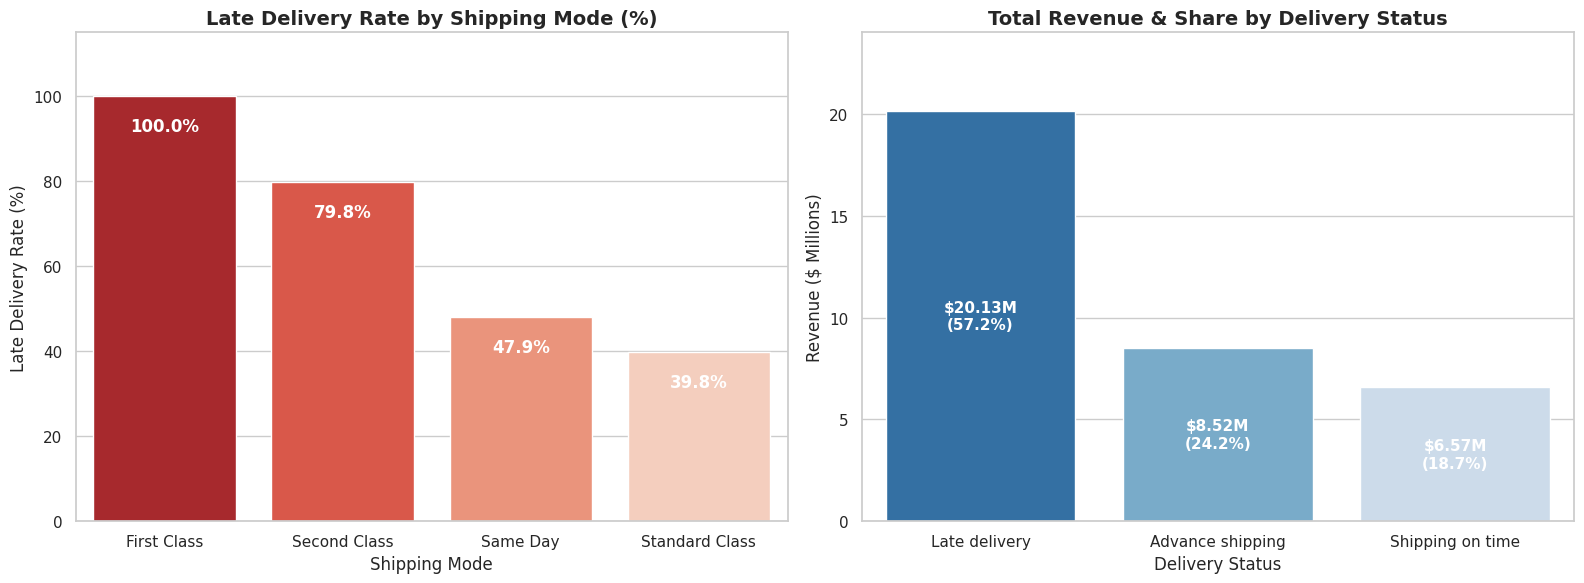

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Late Delivery Rate by Shipping Mode
df_shipping = pd.read_sql_query(q1, conn)
sns.barplot(
    data=df_shipping, 
    x='shipping_mode', 
    y='late_rate_pct',
    hue='shipping_mode',
    palette='Reds_r', 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Late Delivery Rate by Shipping Mode (%)', fontsize=14, weight='bold')
axes[0].set_ylabel('Late Delivery Rate (%)')
axes[0].set_xlabel('Shipping Mode')
axes[0].set_ylim(0, 115)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", 
                    (p.get_x() + p.get_width() / 2., p.get_height() - 7),
                    ha='center', va='center', color='white', weight='bold')

# Plot 2: Total Revenue & Share by Delivery Status
df_finance = pd.read_sql_query(q3, conn)
total_revenue_all = df_finance['total_revenue'].sum()
df_finance['total_revenue_millions'] = df_finance['total_revenue'] / 1e6
df_finance['revenue_pct'] = (df_finance['total_revenue'] / total_revenue_all) * 100.0

sns.barplot(
    data=df_finance, 
    x='delivery_status', 
    y='total_revenue_millions',
    hue='delivery_status',
    palette='Blues_r', 
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Total Revenue & Share by Delivery Status', fontsize=14, weight='bold')
axes[1].set_ylabel('Revenue ($ Millions)')
axes[1].set_xlabel('Delivery Status')
axes[1].set_ylim(0, 24)

# Add both $ Millions and % share directly on the bars
for p, (_, row) in zip(axes[1].patches, df_finance.iterrows()):
    label_text = f"${row['total_revenue_millions']:.2f}M\n({row['revenue_pct']:.1f}%)"
    axes[1].annotate(label_text, 
                    (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                    ha='center', va='center', color='white', weight='bold', fontsize=11)

plt.tight_layout()
plt.show()